# 02 Model: from baseline to a cost-based threshold

**Step 4:** split the data and set the baseline every model must beat.
**Step 5:** logistic regression, then a random forest.
**Step 6:** evaluate on the test set and choose the threshold from business costs.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
clean = pd.read_csv("../data/processed/churn_clean.csv")
FEATURES = [c for c in clean.columns if c not in ("customer_id", "churn")]
X, y = clean[FEATURES], clean["churn"]

## 1. Train/test split

25% of customers are held back as a test set and not touched until Step 6. The split is **stratified** on churn so both sets have the same churn rate (about 15.6%). Without stratification a small test set can end up with noticeably more or fewer churners just by chance.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
ids_test = clean.loc[X_test.index, "customer_id"]
print(f"Train: {len(X_train)} customers, churn rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} customers, churn rate {y_test.mean():.1%}")

Train: 2137 customers, churn rate 15.6%
Test:  713 customers, churn rate 15.7%


## 2. Baseline: predict 'no churn' for everyone

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = baseline.predict(X_test)
print(f"Accuracy:  {accuracy_score(y_test, pred):.1%}")
print(f"Recall:    {recall_score(y_test, pred):.1%}  (churners caught)")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.1%}  (undefined: it flags nobody)")

Accuracy:  84.3%
Recall:    0.0%  (churners caught)
Precision: 0.0%  (undefined: it flags nobody)


The baseline is about 84% accurate and catches **zero** churners. This is the accuracy trap: on imbalanced data, a useless model can look good. Every model from here is judged on recall, precision and ranking quality, not accuracy.

---
# Step 5: Models

## 3. Logistic regression

A logistic regression is the right first model: it is fast, and its coefficients can be explained to a manager. Features are on very different scales (seconds of use runs into the thousands, complaints is 0 or 1), so they are **standardised** first. That lets the coefficients be compared: each one is the change in log-odds of churn for a one standard deviation increase in that feature.

I do **not** use `class_weight="balanced"` here. Re-weighting would push the predicted probabilities upwards, and Step 7 needs honest probabilities to calculate expected loss. The imbalance is handled where it belongs: in the choice of threshold.

Models are compared with 5-fold cross-validation on the training set only, so the test set stays untouched.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision"}

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv_lr = cross_validate(logreg, X_train, y_train, cv=cv, scoring=scoring)
pd.Series({k.replace("test_", ""): v.mean() for k, v in cv_lr.items() if k.startswith("test_")}).round(3)

roc_auc      0.931
pr_auc       0.750
recall       0.458
precision    0.785
dtype: float64

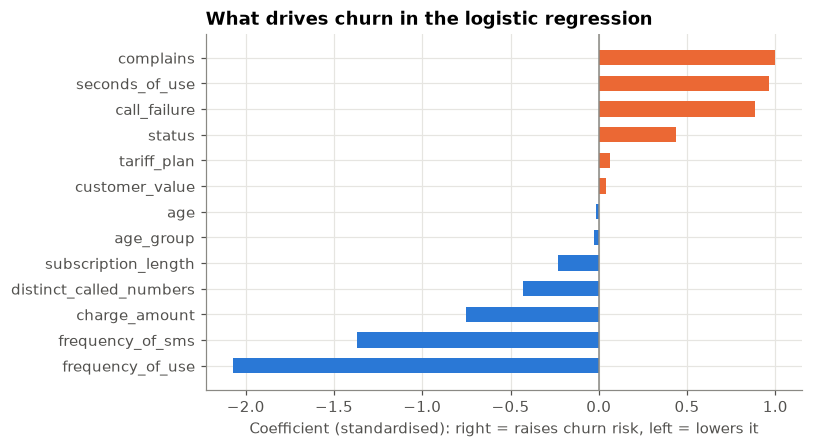

frequency_of_use   -2.07
frequency_of_sms   -1.37
complains           1.00
seconds_of_use      0.96
call_failure        0.88
charge_amount      -0.75
dtype: float64

In [5]:
logreg.fit(X_train, y_train)
coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(coefs.index, coefs.values, color=[ORANGE if v > 0 else BLUE for v in coefs.values], height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlabel("Coefficient (standardised): right = raises churn risk, left = lowers it")
ax.set_title("What drives churn in the logistic regression")
fig.savefig("../figures/logreg_coefficients.png")
plt.show()
coefs.reindex(coefs.abs().sort_values(ascending=False).index).round(2).head(6)

In [6]:
odds = np.exp(coefs)
for f in ["frequency_of_use", "frequency_of_sms", "complains", "seconds_of_use"]:
    print(f"{f:18s} coefficient {coefs[f]:+.2f} -> odds of churn x{odds[f]:.2f} per standard deviation")

frequency_of_use   coefficient -2.07 -> odds of churn x0.13 per standard deviation
frequency_of_sms   coefficient -1.37 -> odds of churn x0.25 per standard deviation
complains          coefficient +1.00 -> odds of churn x2.72 per standard deviation
seconds_of_use     coefficient +0.96 -> odds of churn x2.62 per standard deviation


**The three strongest effects, in words** (each holding the other features fixed):

1. **Frequency of use** has the largest effect: one standard deviation more calls (about 57 calls over nine months) cuts the odds of churning to roughly an eighth. Customers who keep using the network stay.
2. **Frequency of SMS** points the same way: active texters rarely leave.
3. **Complaints** raise the odds of churn by about 2.7 times. A complaint is a direct statement of dissatisfaction.

**A trap worth knowing:** `seconds_of_use` gets a *positive* coefficient, which seems to say that talking more raises churn risk. The raw data says the opposite (churners talked about a third as much). The sign flips because seconds of use, number of calls and customer value move together closely. Once the model already knows how many calls someone made, the extra seconds carry little new information, and the model splits the shared effect between correlated features in ways that should not be read one by one. This is called **multicollinearity**. The reliable reading is the group story: low usage means high risk.

## 4. Random forest

A random forest can capture non-linear effects and interactions (for example, a complaint matters more for a customer whose usage is already dropping) that a logistic regression cannot. Scaling is not needed for trees.

In [7]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
cv_rf = cross_validate(forest, X_train, y_train, cv=cv, scoring=scoring)

comparison = pd.DataFrame({
    "Logistic regression": {k.replace("test_", ""): v.mean() for k, v in cv_lr.items() if k.startswith("test_")},
    "Random forest": {k.replace("test_", ""): v.mean() for k, v in cv_rf.items() if k.startswith("test_")},
}).round(3)
comparison

,Logistic regression,Random forest
roc_auc,0.931,0.984
pr_auc,0.750,0.932
recall,0.458,0.799
precision,0.785,0.894


Recall and precision above use the default 0.5 threshold. ROC AUC and PR AUC do not depend on a threshold, so they are the fairer way to compare how well each model **ranks** customers.

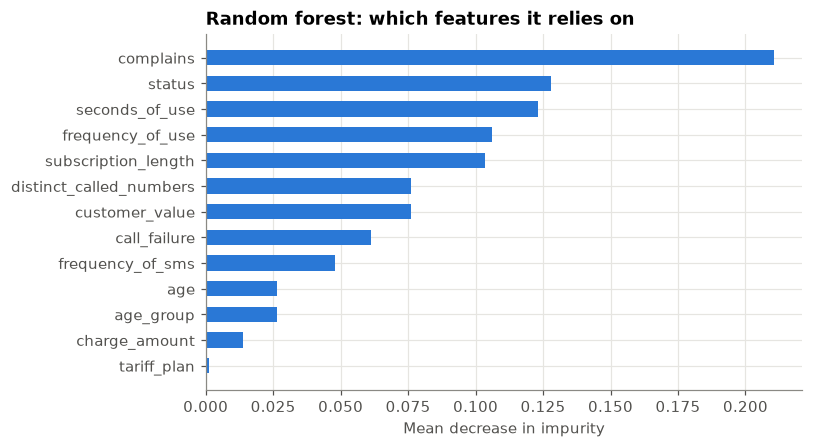

In [8]:
forest.fit(X_train, y_train)
importance = pd.Series(forest.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random forest: which features it relies on")
fig.savefig("../figures/forest_importance.png")
plt.show()

## 5. Robustness check: how much does the model lean on `status`?

In [9]:
no_status = [f for f in FEATURES if f != "status"]
cv_rf_ns = cross_validate(forest, X_train[no_status], y_train, cv=cv, scoring=["roc_auc", "average_precision"])
print(f"Random forest with status:    ROC AUC {cv_rf['test_roc_auc'].mean():.3f}, PR AUC {cv_rf['test_pr_auc'].mean():.3f}")
print(f"Random forest without status: ROC AUC {cv_rf_ns['test_roc_auc'].mean():.3f}, PR AUC {cv_rf_ns['test_average_precision'].mean():.3f}")

Random forest with status:    ROC AUC 0.984, PR AUC 0.932
Random forest without status: ROC AUC 0.981, PR AUC 0.909


Removing `status` lowers the scores only slightly, because the usage columns carry much of the same "gone quiet" signal. So even if the documentation were wrong about when `status` was recorded, the model would not collapse. That makes keeping it a low-risk decision.

**Choice for the next step:** the random forest ranks churners better on both threshold-free metrics, so it goes forward. The logistic regression stays as the explainable reference.

---
# Step 6: Evaluate and choose the threshold

## 6. Turning the business costs into a threshold

The README sets the costs: a contact costs **R140** (agent time plus the offer), and a churner who leaves takes about **R3,000** of future revenue. One more assumption is needed, because a call does not save everyone: I assume a retention offer persuades **30%** of genuine churners to stay.

So for a customer with churn probability *p*, contacting them is worth it on average when

`p x 30% x R3,000 > R140`, which gives `p > 140 / 900 = 0.156`.

That is far below the default of 0.5. To check the formula against the model, I compute the net value of every threshold using **out-of-fold predictions on the training set** (each customer is scored by a model that did not see them), then pick the threshold that earns the most. The test set is still untouched.

In [10]:
from sklearn.model_selection import cross_val_predict

CONTACT_COST, SAVE_RATE, VALUE_IF_SAVED = 140, 0.30, 3000

def net_value(y_true, proba, threshold):
    flagged = proba >= threshold
    tp = (flagged & (y_true == 1)).sum()
    return tp * SAVE_RATE * VALUE_IF_SAVED - flagged.sum() * CONTACT_COST

oof = cross_val_predict(forest, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.02, 0.96, 0.01), 2)
values = np.array([net_value(y_train.values, oof, t) for t in thresholds])
best_t = float(thresholds[values.argmax()])
print(f"Break-even formula: {CONTACT_COST / (SAVE_RATE * VALUE_IF_SAVED):.3f}")
print(f"Best threshold on training data: {best_t:.2f}")

Break-even formula: 0.156
Best threshold on training data: 0.23


The data-driven best (around 0.2) sits close to the formula's 0.156. They differ a little because the forest's probabilities are not perfectly calibrated and the net-value curve is fairly flat in that region, so any threshold between about 0.15 and 0.45 earns almost the same. The important point is the gap to 0.5: the default would leave real money on the table.

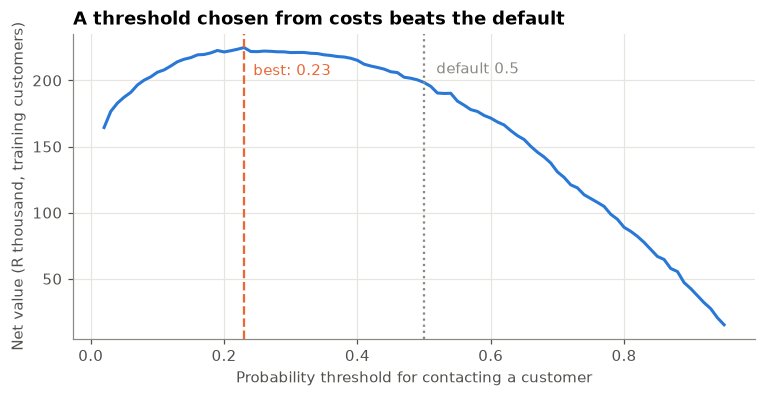

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(thresholds, values / 1000, color=BLUE)
ax.axvline(best_t, color=ORANGE, linestyle="--", linewidth=1.5)
ax.axvline(0.5, color=GREY, linestyle=":", linewidth=1.5)
ax.annotate(f"best: {best_t:.2f}", (best_t, values.max() / 1000), xytext=(6, -18), textcoords="offset points", color=ORANGE)
ax.annotate("default 0.5", (0.5, values[thresholds == 0.5][0] / 1000), xytext=(8, 6), textcoords="offset points", color=GREY)
ax.set_xlabel("Probability threshold for contacting a customer")
ax.set_ylabel("Net value (R thousand, training customers)")
ax.set_title("A threshold chosen from costs beats the default")
fig.savefig("../figures/net_value_by_threshold.png")
plt.show()

## 7. Test set results (first and only look)

In [12]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             f1_score, ConfusionMatrixDisplay, PrecisionRecallDisplay)

p_lr = logreg.predict_proba(X_test)[:, 1]
p_rf = forest.predict_proba(X_test)[:, 1]

def summary(name, proba, t):
    pred = (proba >= t).astype(int)
    return {"model": name, "threshold": t, "ROC AUC": roc_auc_score(y_test, proba),
            "PR AUC": average_precision_score(y_test, proba),
            "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
            "F1": f1_score(y_test, pred), "flagged": int(pred.sum())}

results = pd.DataFrame([summary("Logistic regression", p_lr, 0.5), summary("Random forest", p_rf, 0.5),
                        summary("Random forest", p_rf, best_t)]).round(3)
results

,model,threshold,ROC AUC,PR AUC,recall,precision,F1,flagged
0,Logistic regression,0.50,0.932,0.778,0.482,0.831,0.610,65
1,Random forest,0.50,0.983,0.932,0.786,0.917,0.846,96
2,Random forest,0.23,0.983,0.932,0.946,0.711,0.812,149


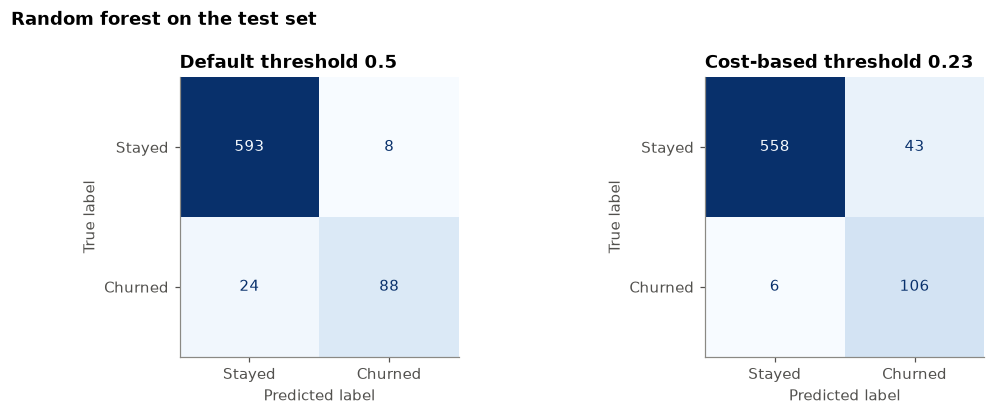

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, t, title in zip(axes, [0.5, best_t], ["Default threshold 0.5", f"Cost-based threshold {best_t:.2f}"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_rf >= t).astype(int)),
                           display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Random forest on the test set", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../figures/confusion_matrices.png")
plt.show()

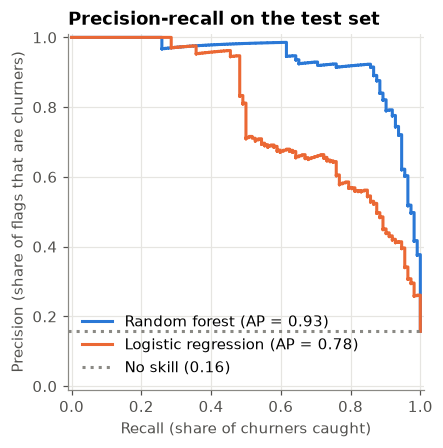

In [14]:
fig, ax = plt.subplots(figsize=(6, 4.2))
PrecisionRecallDisplay.from_predictions(y_test, p_rf, ax=ax, name="Random forest", curve_kwargs={"color": BLUE})
PrecisionRecallDisplay.from_predictions(y_test, p_lr, ax=ax, name="Logistic regression", curve_kwargs={"color": ORANGE})
ax.axhline(y_test.mean(), color=GREY, linestyle=":", label=f"No skill ({y_test.mean():.2f})")
ax.set_xlabel("Recall (share of churners caught)")
ax.set_ylabel("Precision (share of flags that are churners)")
ax.set_title("Precision-recall on the test set")
ax.legend(loc="lower left")
fig.savefig("../figures/precision_recall_curve.png")
plt.show()

## 8. What the model catches, in money

In [15]:
test = pd.DataFrame({"customer_id": ids_test.values, "churn": y_test.values,
                     "customer_value": X_test["customer_value"].values, "p_churn": p_rf})
test["flagged"] = test.p_churn >= best_t
churners = test[test.churn == 1]
caught_value = churners.loc[churners.flagged, "customer_value"].sum()
print(f"Churners in test set: {len(churners)}; caught: {churners.flagged.sum()} ({churners.flagged.mean():.0%})")
print(f"Customer value of churners caught: {caught_value:,.0f} of {churners.customer_value.sum():,.0f} "
      f"({caught_value / churners.customer_value.sum():.0%}) dataset units")
tp = int((test.flagged & (test.churn == 1)).sum())
n_flag = int(test.flagged.sum())
print(f"Rand view (README assumptions): {n_flag} contacts cost R{n_flag * CONTACT_COST:,}; "
      f"expected saves {tp * SAVE_RATE:.0f} customers worth R{tp * SAVE_RATE * VALUE_IF_SAVED:,.0f}; "
      f"net R{net_value(test.churn.values, test.p_churn.values, best_t):,.0f}")

Churners in test set: 112; caught: 106 (95%)
Customer value of churners caught: 16,369 of 17,279 (95%) dataset units
Rand view (README assumptions): 149 contacts cost R20,860; expected saves 32 customers worth R95,400; net R74,540


## 9. Capacity check

The team can contact about 300 of roughly 2,850 customers a quarter, about 10.5% of the base. On the test set that is about 75 contacts.

In [16]:
capacity = round(len(test) * 300 / len(clean))
print(f"Capacity on the test set: {capacity} contacts; flagged by the threshold: {n_flag}")

Capacity on the test set: 75 contacts; flagged by the threshold: 149


The threshold flags more customers than the team can reach, so the threshold alone is not the final answer. When capacity binds, the question becomes *which* flagged customers to call first. That is Step 7: rank by expected loss.

In [17]:
test.to_csv("../data/processed/test_scored.csv", index=False)
pd.Series({"threshold": best_t, "capacity_test": capacity}).to_json("../data/processed/decision_settings.json")